<a href="https://colab.research.google.com/github/jaretorx/Proyecto-final-pia-modelado/blob/main/PIA_Modelado_Robot_Planar_2GDL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PIA | Modelado y simulación de un manipulador planar de 2 GDL
**UANL · FIME · Modelado y Simulación de Sistemas Mecatrónicos**  
**Duración de la simulación: 10 s**

Esta notebook implementa un manipulador RR que se mueve en un plano **vertical**. Se modelan inercia, fuerzas centrífugas y de Coriolis, gravedad, fricción viscosa y pares motores. Se utiliza un control PD con compensación de gravedad como excitación de prueba; **no forma parte de la deducción del modelo**. Los valores físicos son un caso ilustrativo, no mediciones del robot del libro.

**Modelo:** $M(q)\ddot q + C(q,\dot q)\dot q + g(q) + f(\dot q)=\tau$.

## 1. Parámetros
Se supone un brazo uniforme por eslabón, de modo que $r_i=L_i/2$ y $I_i=m_i L_i^2/12$. Las distancias se expresan en metros, las masas en kg, las inercias en kg·m² y los pares en N·m.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation

p = dict(L1=0.55, L2=0.40, m1=1.20, m2=0.80, r1=0.275, r2=0.20, g=9.81, b1=0.12, b2=0.08)
p['I1'] = p['m1'] * p['L1']**2 / 12
p['I2'] = p['m2'] * p['L2']**2 / 12
Kp = np.diag([24.0, 18.0])
Kd = np.diag([9.0, 7.0])
q_deseada = np.array([np.pi/3, -np.pi/4])  # rad
x0 = np.array([0.15, -0.20, 0.0, 0.0]) # [q1, q2, dq1, dq2]
print('Parámetros e inercias:', p)

Parámetros e inercias: {'L1': 0.55, 'L2': 0.4, 'm1': 1.2, 'm2': 0.8, 'r1': 0.275, 'r2': 0.2, 'g': 9.81, 'b1': 0.12, 'b2': 0.08, 'I1': 0.030250000000000003, 'I2': 0.01066666666666667}


## 2. Modelo dinámico Euler–Lagrange
Escribimos $h=m_2L_1r_2\sin(q_2)$. Se adopta la convención $q_2$ relativo al primer eslabón. La matriz $C$ no es única, pero el producto $C(q,\dot q)\dot q$ usado aquí coincide con los términos centrífugos y de Coriolis deducidos del lagrangiano.

In [2]:
def matrices(q, dq):
    q1, q2 = q
    v1, v2 = dq
    L1, r1, r2, m1, m2, I1, I2, g = [p[k] for k in ('L1','r1','r2','m1','m2','I1','I2','g')]
    h = m2 * L1 * r2 * np.sin(q2)
    M11 = I1 + I2 + m1*r1**2 + m2*(L1**2 + r2**2 + 2*L1*r2*np.cos(q2))
    M12 = I2 + m2*(r2**2 + L1*r2*np.cos(q2))
    M22 = I2 + m2*r2**2
    M = np.array([[M11,M12],[M12,M22]])
    C = np.array([[-h*v2,-h*(v1+v2)],[h*v1,0.0]])
    G = np.array([(m1*r1 + m2*L1)*g*np.cos(q1) + m2*r2*g*np.cos(q1+q2),
                  m2*r2*g*np.cos(q1+q2)])
    F = np.array([p['b1']*v1, p['b2']*v2])
    return M,C,G,F

# Verificación de inercia simétrica definida positiva en distintas configuraciones
for a in np.linspace(-np.pi,np.pi,9):
    M,_,_,_=matrices(np.array([0.1,a]),np.zeros(2))
    assert np.allclose(M,M.T) and np.min(np.linalg.eigvalsh(M))>0
print('Comprobación: matriz M simétrica y definida positiva.')

Comprobación: matriz M simétrica y definida positiva.


## 3. Pares de control y simulación numérica
El par mandado es $\tau=g(q)+K_p(q_d-q)-K_d\dot q$. La aceleración se obtiene resolviendo el sistema lineal $M(q)\ddot q=\tau-C(q,\dot q)\dot q-g(q)-f(\dot q)$ con `numpy.linalg.solve`, sin invertir explícitamente la matriz.

In [3]:
def ecuaciones_estado(t, x):
    q, dq = x[:2], x[2:]
    M,C,G,F = matrices(q,dq)
    tau = G + Kp @ (q_deseada-q) - Kd @ dq
    ddq = np.linalg.solve(M, tau - C @ dq - G - F)
    return np.r_[dq, ddq]

t = np.linspace(0.0, 10.0, 1001)
sol = solve_ivp(ecuaciones_estado, (0.0,10.0), x0, t_eval=t, rtol=1e-9, atol=1e-11, max_step=0.02)
assert sol.success, sol.message
q, dq = sol.y[:2], sol.y[2:]
error_final = np.rad2deg(q_deseada - q[:,-1])
print('Posiciones finales (grados):', np.round(np.rad2deg(q[:,-1]),6))
print('Errores finales (grados):', np.round(error_final,8))

Posiciones finales (grados): [ 60. -45.]
Errores finales (grados): [ 0. -0.]


## 4. Posición angular de las articulaciones durante 10 s

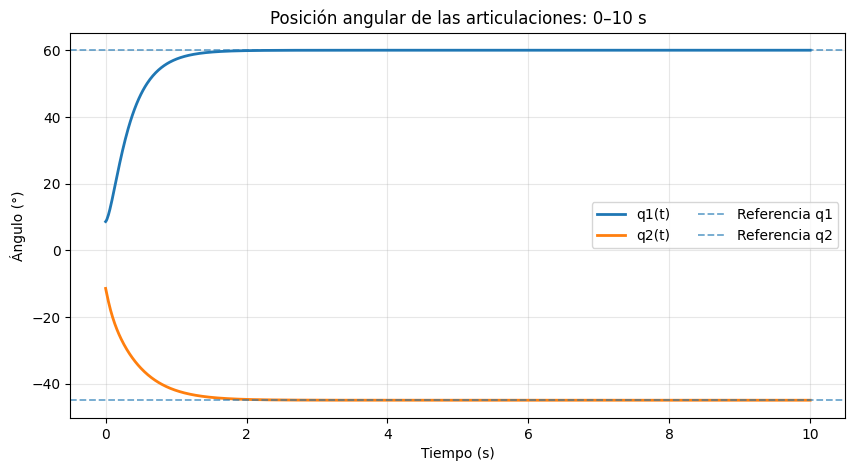

In [4]:
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(t,np.rad2deg(q[0]),label='q1(t)',lw=2)
ax.plot(t,np.rad2deg(q[1]),label='q2(t)',lw=2)
for j in (0,1): ax.axhline(np.rad2deg(q_deseada[j]),ls='--',lw=1.3,alpha=.65,label=f'Referencia q{j+1}')
ax.set(xlabel='Tiempo (s)',ylabel='Ángulo (°)',title='Posición angular de las articulaciones: 0–10 s')
ax.grid(alpha=.3); ax.legend(ncol=2); plt.show()

## 5. Pares de los dos motores

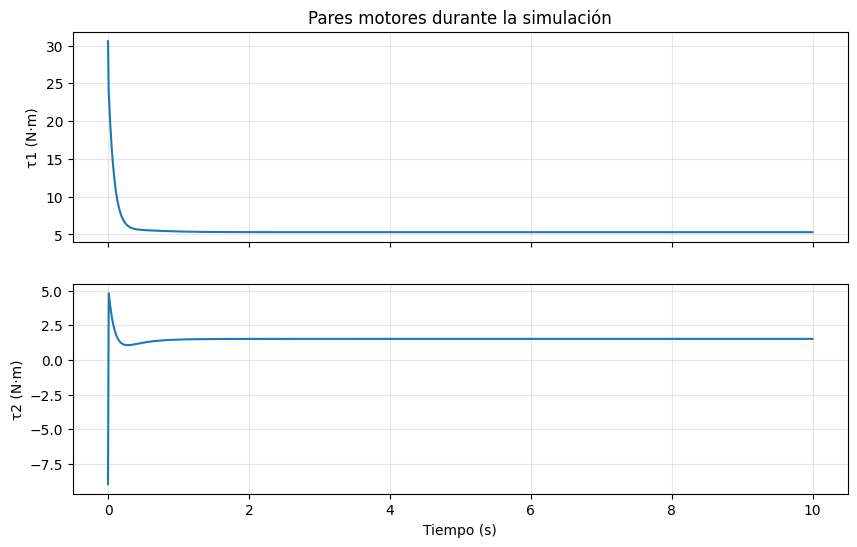

In [5]:
torques = np.array([matrices(q[:,i],dq[:,i])[2] + Kp @ (q_deseada-q[:,i]) - Kd @ dq[:,i] for i in range(len(t))])
fig,axs=plt.subplots(2,1,figsize=(10,6),sharex=True)
for j,ax in enumerate(axs):
    ax.plot(t,torques[:,j]);ax.set_ylabel(f'τ{j+1} (N·m)');ax.grid(alpha=.3)
axs[1].set_xlabel('Tiempo (s)');axs[0].set_title('Pares motores durante la simulación');plt.show()

## 6. Posición geométrica del robot

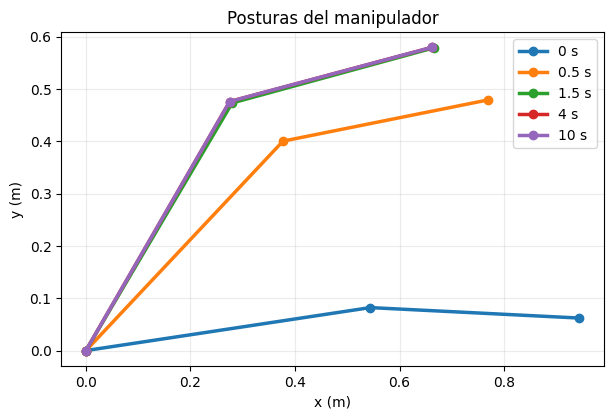

In [6]:
def puntos_robot(q):
    q1,q2=q
    P0=np.array([0.,0.])
    P1=P0 + p['L1']*np.array([np.cos(q1),np.sin(q1)])
    P2=P1 + p['L2']*np.array([np.cos(q1+q2),np.sin(q1+q2)])
    return np.stack([P0,P1,P2])

fig,ax=plt.subplots(figsize=(7,7))
for ti in [0,0.5,1.5,4,10]:
    a=np.argmin(np.abs(t-ti)); XY=puntos_robot(q[:,a])
    ax.plot(XY[:,0],XY[:,1],'-o',lw=2.5,label=f'{ti:g} s')
ax.set_aspect('equal');ax.set(xlabel='x (m)',ylabel='y (m)',title='Posturas del manipulador')
ax.legend();ax.grid(alpha=.25);plt.show()

## 7. Animación reproducible (opcional en Colab/Jupyter)
La celda siguiente crea la animación en línea. **En GitHub**, el renderizado de HTML interactivo puede no aparecer; por eso las gráficas estáticas de las celdas anteriores sí permanecen visibles.

In [7]:
# Para activar la animación, ejecute esta celda en Colab o Jupyter.
fig,ax=plt.subplots(figsize=(6,6))
lim = p['L1']+p['L2']+0.1
ax.set(xlim=(-lim,lim),ylim=(-lim,lim),xlabel='x (m)',ylabel='y (m)',title='Movimiento del manipulador (10 s)')
ax.set_aspect('equal'); ax.grid(alpha=.2)
line, = ax.plot([],[],'-o',lw=5,markersize=8)
stamp=ax.text(.05,.94,'',transform=ax.transAxes)
def actualizar(frame):
    X=puntos_robot(q[:,frame]);line.set_data(X[:,0],X[:,1]);stamp.set_text(f't = {t[frame]:.2f} s')
    return line,stamp
anim=FuncAnimation(fig,actualizar,frames=np.arange(0,len(t),10),interval=70,blit=True)
plt.close(fig)
display(HTML(anim.to_jshtml()))

## 8. Interpretación y limitaciones
- El control PD con compensación de gravedad lleva las dos articulaciones hacia las referencias de **60°** y **−45°** durante 10 segundos.
- La fricción es viscosa, lineal y siempre opuesta a la velocidad.
- Los parámetros son valores de prueba; no se incluyen saturación de motor, límites angulares, holguras ni contacto con objetos.
- Para reproducir: ejecutar todas las celdas en orden. Requiere `numpy`, `scipy`, `matplotlib` e `IPython`.